## **Data Loading**

In [2]:
import pandas as pd

titles_df = pd.read_csv('./data/titles.csv')
titles_df.head()

,id,title,type,description,release_year,age_certification,runtime,genres,production_countries,seasons,imdb_id,imdb_score,imdb_votes,tmdb_popularity,tmdb_score
0,ts300399,Five Came Back: The Reference Films,SHOW,This collection includes 12 World War II-era p...,1945,TV-MA,51,['documentation'],['US'],1.0,NaN,NaN,NaN,0.600,NaN
1,tm84618,Taxi Driver,MOVIE,A mentally unstable Vietnam War veteran works ...,1976,R,114,"['drama', 'crime']",['US'],NaN,tt0075314,8.2,808582.0,40.965,8.179
2,tm154986,Deliverance,MOVIE,Intent on seeing the Cahulawassee River before...,1972,R,109,"['drama', 'action', 'thriller', 'european']",['US'],NaN,tt0068473,7.7,107673.0,10.010,7.300
3,tm127384,Monty Python and the Holy Grail,MOVIE,"King Arthur, accompanied by his squire, recrui...",1975,PG,91,"['fantasy', 'action', 'comedy']",['GB'],NaN,tt0071853,8.2,534486.0,15.461,7.811
4,tm120801,The Dirty Dozen,MOVIE,12 American military prisoners in World War II...,1967,NaN,150,"['war', 'action']","['GB', 'US']",NaN,tt0061578,7.7,72662.0,20.398,7.600


In [3]:
credits_df = pd.read_csv('./data/credits.csv')
credits_df.head()

,person_id,id,name,character,role
0,3748,tm84618,Robert De Niro,Travis Bickle,ACTOR
1,14658,tm84618,Jodie Foster,Iris Steensma,ACTOR
2,7064,tm84618,Albert Brooks,Tom,ACTOR
3,3739,tm84618,Harvey Keitel,Matthew 'Sport' Higgins,ACTOR
4,48933,tm84618,Cybill Shepherd,Betsy,ACTOR


# NULL Value Checks

In [4]:
(titles_df.isnull().sum()).to_frame().T

,id,title,type,description,release_year,age_certification,runtime,genres,production_countries,seasons,imdb_id,imdb_score,imdb_votes,tmdb_popularity,tmdb_score
0,0,1,0,18,0,2619,0,0,0,3744,403,482,498,91,311


In [5]:
(credits_df.isnull().sum()).to_frame().T

,person_id,id,name,character,role
0,0,0,0,9772,0


#### **Percentage of missing values per column**

In [6]:
(titles_df.isnull().mean() * 100).to_frame(name='null_pct').T

,id,title,type,description,release_year,age_certification,runtime,genres,production_countries,seasons,imdb_id,imdb_score,imdb_votes,tmdb_popularity,tmdb_score
null_pct,0.0,0.017094,0.0,0.307692,0.0,44.769231,0.0,0.0,0.0,64.0,6.888889,8.239316,8.512821,1.555556,5.316239


In [7]:
(credits_df.isna().mean() * 100).to_frame(name='null_pct').T

,person_id,id,name,character,role
null_pct,0.0,0.0,0.0,12.56025,0.0


#### **Grand Total of all null values across the entire DataFrame**

In [8]:
titles_df.isna().sum().sum()

np.int64(8167)

In [9]:
credits_df.isna().sum().sum()

np.int64(9772)

## Duplicate Checks

##### The literal same row ingested twice 

In [10]:
titles_df.duplicated(subset=['id'], keep=False).sum()

np.int64(0)

In [11]:
titles_df.duplicated(subset=["imdb_id"], keep=False).sum()

np.int64(403)

In [12]:
titles_df.duplicated(subset=["title", "release_year"], keep=False).sum()

np.int64(8)

## **Shows with one or more than one seasons.**

In [13]:
shows = titles_df[titles_df['type'] == 'SHOW']
shows.groupby('type')['type'].count()

type
SHOW    2106
Name: type, dtype: int64

In [14]:
(shows['seasons']>=1).sum()

np.int64(2106)

### How many movies are present based on different age-certification levels

In [15]:
titles_df.shape

(5850, 15)

In [16]:
titles_df['age_certification'].value_counts().reset_index()

,age_certification,count
0,TV-MA,883
1,R,556
2,TV-14,474
3,PG-13,451
4,PG,233
5,TV-PG,188
6,G,124
7,TV-Y7,120
8,TV-Y,107
9,TV-G,79


In [17]:
pd.crosstab(titles_df['type'], titles_df['age_certification'])

age_certification,G,NC-17,PG,PG-13,R,TV-14,TV-G,TV-MA,TV-PG,TV-Y,TV-Y7
type,,,,,,,,,,,
MOVIE,124,16,233,451,556,0,0,0,0,0,0
SHOW,0,0,0,0,0,474,79,883,188,107,120


#### **R-rated movies by Title**

In [18]:
titles_df[(titles_df['age_certification'] == 'R') & (titles_df['type'] == 'MOVIE')]['title'].head(10)

1                        Taxi Driver
2                        Deliverance
6                      Life of Brian
7                        Dirty Harry
8                   Bonnie and Clyde
9                    The Blue Lagoon
12    Richard Pryor: Live in Concert
16                               FTA
36                        GoodFellas
37                 Full Metal Jacket
Name: title, dtype: str

In [19]:
titles_df.query("`age_certification` == 'R' and type == 'MOVIE'")["title"].head(10)

1                        Taxi Driver
2                        Deliverance
6                      Life of Brian
7                        Dirty Harry
8                   Bonnie and Clyde
9                    The Blue Lagoon
12    Richard Pryor: Live in Concert
16                               FTA
36                        GoodFellas
37                 Full Metal Jacket
Name: title, dtype: str

In [20]:
titles_df[titles_df['type'] == 'MOVIE'].groupby('age_certification')['title'].agg(list)

age_certification
G        [Kuch Kuch Hota Hai, Knight Rider 2000, Jerry ...
NC-17    [Bill Hicks: One Night Stand, Aamir, Berserk: ...
PG       [Monty Python and the Holy Grail, Hitler: A Ca...
PG-13    [The Professionals, Awakenings, National Lampo...
R        [Taxi Driver, Deliverance, Life of Brian, Dirt...
Name: title, dtype: object

## R-Movies & TV-MA Shows

In [21]:
r_movies = titles_df[(titles_df['age_certification']=='R') & (titles_df['type']=='MOVIE')]['title'].reset_index(drop=True)

In [22]:
tv_ma_shows = titles_df[(titles_df['age_certification']=='TV-MA')&(titles_df['type']=='SHOW')]['title'].reset_index(drop=True)

In [23]:
result = pd.concat([r_movies, tv_ma_shows], axis=1)
result.columns = ['R Movies', 'TV-MA Shows']

In [24]:
result.head()

,R Movies,TV-MA Shows
0,Taxi Driver,Five Came Back: The Reference Films
1,Deliverance,Monty Python's Fliegender Zirkus
2,Life of Brian,Heartbreak High
3,Dirty Harry,Okupas
4,Bonnie and Clyde,H


In [25]:
clubs_to_compare = {
    'Adult' : ['R','TV-MA','NC-17'],
    'General Audience': ['G','TV-G'],
    'Parental_Guidance': ['PG','TV-PG'],
    'Parents_Strongly_Cautioned': ['PG-13','TV-14'],
    'Children_2-6': ['TV-Y'],
    'Children_7_Or_Above': ['TV-Y7']
}

mapping = {label: group for group, labels in clubs_to_compare.items() for label in labels}
titles_df['rating_group'] = titles_df['age_certification'].map(mapping).fillna('Other')

for group_name, labels in clubs_to_compare.items():
    cols = [titles_df[titles_df['age_certification'] == label]['title'].reset_index(drop=True) for label in labels]
    
    comparison_df = pd.concat(cols)
    comparison_df.columns = labels
    
    print(f"------{group_name} Group-----")
    print(comparison_df.head(10))
    print("\n")

------Adult Group-----
0                       Taxi Driver
1                       Deliverance
2                     Life of Brian
3                       Dirty Harry
4                  Bonnie and Clyde
5                   The Blue Lagoon
6    Richard Pryor: Live in Concert
7                               FTA
8                        GoodFellas
9                 Full Metal Jacket
Name: title, dtype: str


------General Audience Group-----
0                                   Kuch Kuch Hota Hai
1                                    Knight Rider 2000
2    Jerry Seinfeld: I'm Telling You for the Last Time
3                                 Hum Saath Saath Hain
4                                                Muthu
5                                       Minsara Kanavu
6                                   Mr. Bean's Holiday
7                         No Direction Home: Bob Dylan
8                                      Stuart Little 2
9                             Kabhi Khushi Kabhie Gham
Name: t

### Top 10 Movies and Shows

In [26]:
movies_df = titles_df[titles_df['type']=='MOVIE']

reliable_movies = movies_df[movies_df['imdb_votes']>1000]

sorted_movies = reliable_movies.sort_values(
    by=['imdb_score', 'imdb_votes'],
    ascending=[False, False]
)

top_10_shows_per_grp = sorted_movies.groupby('rating_group').apply(lambda x:x.nlargest(10, 'imdb_score')[['title', 'imdb_score', 'imdb_votes']])
top_10_shows_per_grp['rank'] = top_10_shows_per_grp.groupby('rating_group').cumcount() + 1
top_10_shows_per_grp

title  \
rating_group                                                                         
Adult                      36                                           GoodFellas   
                           4818                                 Bo Burnham: Inside   
                           94                                                Se7en   
                           239                                        The Departed   
                           109                              Léon: The Professional   
                           651                                    Django Unchained   
                           3381                    Dave Chappelle: Sticks & Stones   
                           410                                        Black Friday   
                           3447                                       Super Deluxe   
                           98                                               Snatch   
General Audience           578                            Harishchandrachi Factory   
                           419                                              Swades   
                           735                                              Barfi!   
                           434                                      Dil Chahta Hai   
                           768                                     OMG: Oh My God!   
                           4255                                    Sillu Karupatti   
                           168   Jerry Seinfeld: I'm Telling You for the Last Time   
                           553                                             Lakshya   
                           162                                  Kuch Kuch Hota Hai   
                           2738                                     Njan Prakashan   
Other                      4771                                              Major   
                           435                                          Anbe Sivam   
                           2703                              Merku Thodarchi Malai   
                           3791  Best Wishes, Warmest Regards: A Schitt's Creek...   
                           175                             Bill Hicks: Revelations   
                           2168                            Springsteen On Broadway   
                           4170          Emicida: AmarElo - It's All for Yesterday   
                           1282                             Bo Burnham: Make Happy   
                           365                               Louis C.K.: Hilarious   
                           527                               Kannathil Muthamittal   
Parental_Guidance          3271           David Attenborough: A Life on Our Planet   
                           2547                                  C/o Kancharapalem   
                           1274                                          Visaranai   
                           372                                 Like Stars on Earth   
                           3401                       Violet Evergarden: The Movie   
                           3                       Monty Python and the Holy Grail   
                           745                                    Paan Singh Tomar   
                           2528                                Sudani from Nigeria   
                           3320                                              Klaus   
                           347                   Lagaan: Once Upon a Time in India   
Parents_Strongly_Cautioned 237                                           Inception   
                           97                                         Forrest Gump   
                           645                               The Dark Knight Rises   
                           316                                            3 Idiots   
                           1745                          Won't You Be My Neighbor?   
                           2090    

In [27]:
pd.set_option("display.max_rows", None)
shows_df = titles_df[titles_df["type"] == "SHOW"]

reliable_shows = shows_df[shows_df["imdb_votes"] > 1000]

sorted_shows = reliable_shows.sort_values(
    by=["imdb_score", "imdb_votes"], ascending=[False, False]
)

top_10_shows_per_grp = sorted_shows.groupby("rating_group").apply(
    lambda x: x.nlargest(10, "imdb_score")[["title", "imdb_score", "imdb_votes"]]
)
top_10_shows_per_grp["rank"] = top_10_shows_per_grp.groupby("rating_group").cumcount() + 1
top_10_shows_per_grp

title  \
rating_group                                                                  
Adult                      216                                 Breaking Bad   
                           3068                              The Last Dance   
                           3500                                Kota Factory   
                           835                              Attack on Titan   
                           165                                       Okupas   
                           3104                            When They See Us   
                           649                                 Black Mirror   
                           833                               Peaky Blinders   
                           1121                            Better Call Saul   
                           1161                                      Narcos   
Children_2-6               119                         The Magic School Bus   
                           308                                    Octonauts   
                           364                           Masha and the Bear   
                           55                                  Danger Mouse   
                           696               Barbie: Life in the Dreamhouse   
                           117                                    Yu-Gi-Oh!   
                           426                                   Timmy Time   
                           882                              Sofia the First   
                           45                              Thomas & Friends   
                           59                                   Fireman Sam   
Children_7_Or_Above        233                   Avatar: The Last Airbender   
                           1826                                       Hilda   
                           664                          The Legend of Korra   
                           1834                           The Dragon Prince   
                           1263              Trollhunters: Tales of Arcadia   
                           238                   The Spectacular Spider-Man   
                           3214            Kipo and the Age of Wonderbeasts   
                           1334                   Dragons: Race to the Edge   
                           1265                 Voltron: Legendary Defender   
                           4872                          Maya and the Three   
General Audience           3147                                  Our Planet   
                           1753                              Anne with an E   
                           3261                      Julie and the Phantoms   
                           5194               Headspace Guide to Meditation   
                           3333                                 Street Food   
                           125                                     All That   
                           271     Ned's Declassified School Survival Guide   
                           376                 Ben & Holly's Little Kingdom   
                           378                                   Code Lyoko   
                           3432                       The Baby-Sitters Club   
Other                      5283                                   Navillera   
                           3227           Greatest Events of WWII in Colour   
                           1889                              Dave Chappelle   
                           1931                   Norm Macdonald Has a Show   
                           2222                             Prison Playbook   
                           5015                                    Vincenzo   
                           288                                    Offspring   
                           3409                          Arthdal Chronicles   
                           350                                   Kath & Kim   
                           1383          

### Release Year Trends

In [28]:
titles_df['release_year'].unique()

array([1945, 1976, 1972, 1975, 1967, 1969, 1979, 1971, 1980, 1961, 1966,
       1954, 1958, 1977, 1963, 1956, 1960, 1973, 1974, 1959, 1978, 1989,
       1990, 1987, 1984, 1983, 1982, 1986, 1981, 1988, 1985, 2000, 1996,
       1997, 1995, 1994, 1999, 1998, 1993, 1992, 1991, 2008, 2002, 2010,
       2005, 2007, 2004, 2006, 2009, 2003, 2001, 2011, 2012, 2013, 2014,
       2015, 2016, 2018, 2017, 2019, 2020, 2022, 2021])

In [29]:
pd.set_option('display.max_rows',None)
titles_df['release_year'].value_counts().reset_index(name='count')

,release_year,count
0,2019,836
1,2020,814
2,2021,787
3,2018,773
4,2017,563
5,2022,371
6,2016,362
7,2015,223
8,2014,153
9,2013,135


### KPI cards — Executive overview

In [30]:
import pandas as pd, numpy as np
from IPython.display import display, HTML

t = titles_df.copy()
for c in ["release_year", "imdb_score", "imdb_votes"]:
    t[c] = pd.to_numeric(t[c], errors="coerce")

# ---- strategy computations -------------------------------------------------
total = len(t)
show_share = (t["type"] == "SHOW").mean() * 100
n_show, n_movie = int((t["type"] == "SHOW").sum()), int((t["type"] == "MOVIE").sum())

rated = t[(t["imdb_votes"] >= 100) & t["imdb_score"].notna()]
med_score = rated["imdb_score"].median()
pct_75 = (rated["imdb_score"] >= 7.5).mean() * 100
med_votes = rated["imdb_votes"].median()
breakout = int((t["imdb_votes"] >= 10_000).sum()) 

y_max = int(t["release_year"].max())
fresh = (t["release_year"] >= y_max - 4).mean() * 100

print(
    "credits.role values ->", credits_df["role"].value_counts().to_dict()
)  
cr_dir = credits_df[credits_df["role"].astype(str).str.upper().str.contains("DIRECTOR")]
dstat = (
    cr_dir.merge(t[["id", "imdb_score"]], on="id", how="left")
    .groupby("name")
    .agg(n_titles=("id", "nunique"), avg=("imdb_score", "mean"))
    .query("n_titles>=3 and avg>=7.0")
    .sort_values("n_titles", ascending=False)
)
n_bank = len(dstat)
top_dir, top_n, top_avg = (
    (dstat.index[0], int(dstat["n_titles"].iloc[0]), dstat["avg"].iloc[0])
    if n_bank
    else ("—", 0, 0)
)

# ---- integrity computations ------------------------------------------------
cert_null = int(t["age_certification"].isna().sum())
cert_cov = (1 - cert_null / total) * 100
rated_cov = len(rated) / total * 100
link_cov = t["id"].isin(credits_df["id"]).mean() * 100  # join on id, NOT imdb_id


# ---- render ----------------------------------------------------------------
def card(value, label, ctx, accent):
    return (
        f'<div style="flex:1 1 150px;min-width:150px;background:#fff;border-left:5px solid {accent};'
        f'border-radius:8px;padding:14px 16px;box-shadow:0 1px 3px rgba(0,0,0,.08);">'
        f'<div style="font:700 26px/1.1 Segoe UI;color:{accent};">{value}</div>'
        f'<div style="font:600 12px Segoe UI;color:#2C3E50;margin-top:4px;text-transform:uppercase;letter-spacing:.4px;">{label}</div>'
        f'<div style="font:400 11px Segoe UI;color:#7f8c8d;margin-top:6px;">{ctx}</div></div>'
    )


BLUE, ORANGE, GREEN, TEAL, PURPLE, SLATE, GREY = (
    "#2C7FB8",
    "#E66101",
    "#27AE60",
    "#16A085",
    "#8E44AD",
    "#34495E",
    "#95A5A6",
)
strategy = "".join(
    [
        card(f"{total:,}", "Total catalog", "snapshot · right edge censored", SLATE),
        card(
            f"{show_share:.0f}%",
            "Format mix",
            f"{n_show:,} series / {n_movie:,} films",
            ORANGE,
        ),
        card(
            f"{med_score:.2f}\u2605",
            "Quality (gated)",
            f"{pct_75:.0f}% of {len(rated):,} rated \u22657.5 (\u2265100 votes)",
            GREEN,
        ),
        card(
            f"{breakout:,}",
            "Breakout reach",
            f"titles \u226510k votes · median {med_votes:,.0f}",
            TEAL,
        ),
        card(
            f"{fresh:.0f}%",
            "Catalog freshness",
            f"released {y_max-4}\u2013{y_max} (5-yr window)",
            PURPLE,
        ),
        card(
            f"{n_bank}",
            "Bankable directors",
            f"\u22653 titles & \u22657.0\u2605 · top: {top_dir} ({top_n}, {top_avg:.1f}\u2605)",
            BLUE,
        ),
    ]
)
integrity = "".join(
    [
        card(
            f"{cert_cov:.0f}%",
            "Certification",
            f"{cert_null:,} unrated = arthouse/structural",
            GREY,
        ),
        card(
            f"{rated_cov:.0f}%",
            "Rated & gated",
            f"n={len(rated):,} behind every \u2605 viz",
            GREY,
        ),
        card(
            f"{link_cov:.0f}%",
            "Credit linkage",
            "titles w/ \u22651 credited person (join on id)",
            GREY,
        ),
    ]
)
html = (
    '<div style="font:700 14px Segoe UI;color:#7f8c8d;margin:6px 0 8px;">CATALOG AT A GLANCE</div>'
    f'<div style="display:flex;gap:12px;flex-wrap:wrap;">{strategy}</div>'
    '<div style="font:700 14px Segoe UI;color:#7f8c8d;margin:14px 0 8px;">DATA COVERAGE (qualifies the above)</div>'
    f'<div style="display:flex;gap:12px;flex-wrap:wrap;">{integrity}</div>'
)
display(HTML(html))

credits.role values -> {'ACTOR': 73251, 'DIRECTOR': 4550}


### Treemap — Catalogue composition

NameError: name 'cnt' is not defined

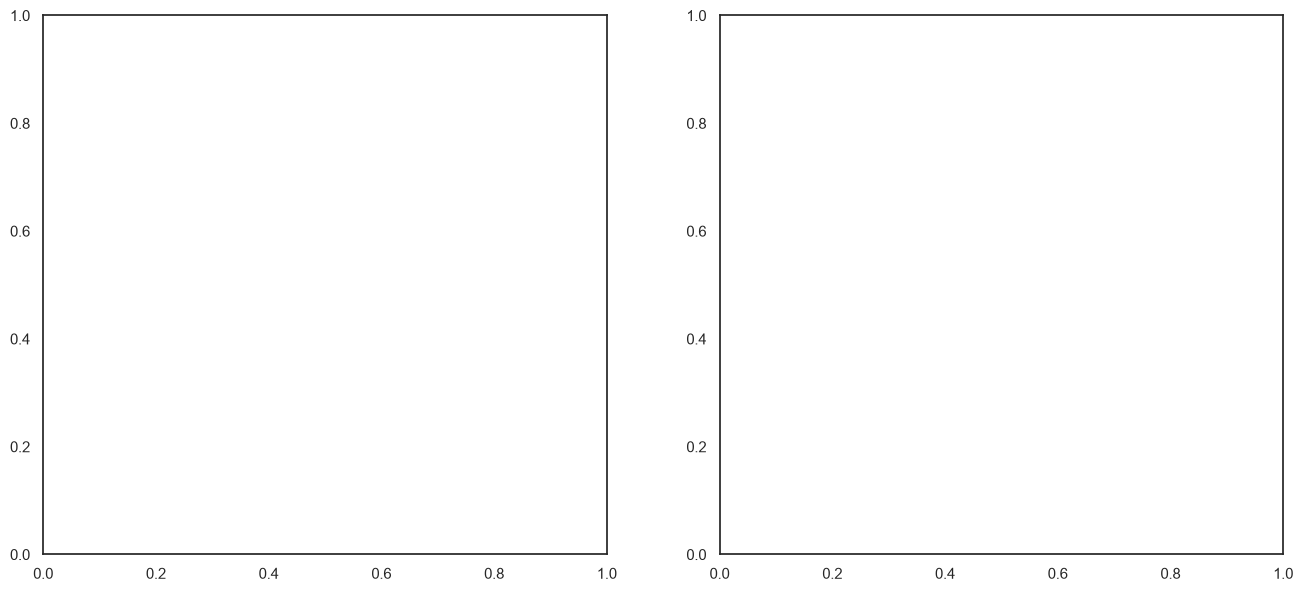

In [ ]:
import squarify, matplotlib.pyplot as plt, seaborn as sns

sns.set_theme(style="white")
palette = {
    "MOVIE": sns.color_palette("Blues_r", 12),
    "SHOW": sns.color_palette("Oranges_r", 12),
}

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
for ax, typ in zip(axes, ["MOVIE", "SHOW"]):
    d = cnt[cnt["type"] == typ].sort_values("pct_within_type", ascending=False)
    sizes, labels = (
        d["pct_within_type"].values,
        (d["genres_l"] + "\n" + d["pct_within_type"].round(1).astype(str) + "%").values,
    )
    squarify.plot(
        sizes=sizes,
        label=labels,
        color=palette[typ][: len(sizes)],
        alpha=0.85,
        text_kwargs={"fontsize": 9, "color": "#1a1a1a"},
        ax=ax,
        pad=True,
    )
    ax.set_title(
        f'{typ}s  (n_tags={int(d["count"].sum()):,})', fontsize=13, fontweight="bold"
    )
    ax.axis("off")
plt.suptitle(
    "Genre share WITHIN each type — compare tile sizes across the two panels",
    fontsize=14,
)
plt.tight_layout()
plt.savefig("./assets/treemap_genre_by_type.png", dpi=150)
plt.show()

### Avg Movie and Show Ratings by Decade

In [ ]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns

sns.set_theme(style="whitegrid")

MIN_VOTES, MIN_N = 100, 3  # tune: votes gate + per-cell sample floor
t = titles_df.copy()
for c in ["release_year", "imdb_score", "imdb_votes"]:
    t[c] = pd.to_numeric(t[c], errors="coerce")
t["decade"] = (t["release_year"] // 10 * 10).astype("Int64")

# gate to trustworthy ratings, then aggregate per (decade, type)
q = t[(t["imdb_votes"] >= MIN_VOTES) & t["imdb_score"].notna()]
agg = (
    q.groupby(["decade", "type"])["imdb_score"]
    .agg(mean="mean", median="median", n="size")
    .reset_index()
)

# wide frames: mean (masked by floor) and n (for labels / the printed table)
mean_w = agg.pivot(index="decade", columns="type", values="mean")
n_w = agg.pivot(index="decade", columns="type", values="n").fillna(0).astype(int)
mean_masked = mean_w.where(n_w >= MIN_N)  # n < MIN_N  ->  NaN -> gap

print("Rated titles per decade × type (the n behind every point):")
print(n_w.to_string())
print("\nMean IMDb score (blank = below floor, do NOT interpret):")
print(mean_masked.round(2).to_string())

# ---- plot: two lines, NaN gaps honoured, each point labelled with mean (n) ----
fig, ax = plt.subplots(figsize=(11, 6))
colors = {"MOVIE": "#2C7FB8", "SHOW": "#E66101"}
for typ in ["MOVIE", "SHOW"]:
    if typ not in mean_masked:
        continue
    x = mean_masked.index.astype(float).values
    y = mean_masked[typ].values
    ax.plot(x, y, marker="o", ms=8, lw=2.2, color=colors[typ], label=typ, zorder=3)
    for xi, yi, ni in zip(x, y, n_w[typ].reindex(mean_masked.index).values):
        if not np.isnan(yi):
            ax.annotate(
                f"{yi:.2f}\n(n={int(ni)})",
                (xi, yi),
                textcoords="offset points",
                xytext=(0, 11),
                ha="center",
                fontsize=8,
                color=colors[typ],
            )

# reference + partial-decade marker
ax.axhline(
    q["imdb_score"].median(),
    color="grey",
    ls=":",
    lw=1,
    label=f"catalog median {q['imdb_score'].median():.2f}",
)
ax.axvspan(2019.5, 2022.5, color="grey", alpha=0.12, zorder=0)
ax.text(
    2021,
    ax.get_ylim()[0] + 0.45,
    "2020s = partial\n(snapshot-censored)",
    ha="center",
    fontsize=8,
    color="dimgray",
)

ax.set_xticks(sorted(mean_masked.index))
ax.set_xlabel("Decade of original release (release_year)")
ax.set_ylabel(f"Mean IMDb score (≥{MIN_VOTES} votes)")
ax.set_ylim(5.5, 8.6)
ax.set_title(
    "Average Rating by Decade — Movies vs Shows", fontsize=13, fontweight="bold"
)
ax.legend(frameon=False, loc="upper left")
ax.grid(alpha=0.25)
plt.tight_layout()
plt.savefig("./assets/avg_rating_by_decade.png", dpi=150)
plt.show()

### **Content Release Trends Over Time**

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
trends = titles_df.groupby(['release_year', 'type']).size().unstack(fill_value=0)

trends.plot(kind='line', figsize=(12,6))
plt.title('Content Release Trends Over Time')
plt.ylabel('Number of Releases')
plt.xlabel('Year')
plt.grid(True)
plt.show()

### **Average IMDB Score**

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(12,6))

sns.lineplot(data=titles_df, x='release_year', y='imdb_score', hue='type', marker='o')

plt.title('Average IMDB Score Over Time')
plt.grid(True)
plt.show()

### **Content Ratings Over Time**

In [ ]:
# Count how many titles in each rating group were released per year
category_trends = (
    titles_df.groupby(["release_year", "rating_group"]).size().unstack(fill_value=0)
)

category_trends.plot(kind="line", figsize=(12, 6))
plt.title("Change in Content Ratings Over Time")
plt.ylabel("Number of Titles")
plt.xlabel("Year")
plt.legend(title="Rating Group", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.grid(True)
plt.show()

In [ ]:
MIN_VOTES = 100
q = titles_df[titles_df["imdb_votes"] >= MIN_VOTES].copy()

qual = (
    q.groupby(["release_year", "type"])["imdb_score"]
    .agg(["mean", "median", "count"])
    .reset_index()
)

qual_long = qual.melt(
    id_vars=["release_year", "type"],
    value_vars=["mean", "median"],
    var_name="stat",
    value_name="imdb_score",
)

plt.figure(figsize=(12, 5))
sns.lineplot(
    data=qual_long, x="release_year", y="imdb_score", hue="type", style='stat' ,marker=True
)
'''sns.lineplot(
    data=qual,
    x="release_year",
    y="median",
    hue="type",
    linestyle="--",
    alpha=0.5,
    label="Median",
)'''
plt.axvline(2020, color="grey", ls=":", lw=1)  # mark where censoring begins
plt.title("Critical Quality by Release Year (titles with ≥100 IMDb votes)")
plt.xlabel("Original Release Year")
plt.ylabel("IMDb Score (0-10)")
plt.legend()
plt.tight_layout()
plt.savefig("./assets/trend_2_quality.png", dpi=150)
plt.show()

### **Top Titles Per Year**

In [ ]:
import ast
df_exploded = titles_df.copy()

df_exploded['genre'] = df_exploded['genres'].apply(lambda x: ast.literal_eval(x) if isinstance(x, str) else x)

df_exploded = df_exploded.explode('genre')

counts = df_exploded.groupby(['release_year', 'rating_group', 'genre', 'title']).size().reset_index(name='title_count')

sorted_counts = counts.sort_values(by=['release_year', 'title_count'], ascending=[True, False])

top_per_year = sorted_counts.groupby('release_year').head(1)

result = top_per_year[['release_year', 'rating_group', 'genre', 'title', 'title_count']]
result.columns = ['Year', 'Category', 'Genre','Title', 'Title_Count']

result

#### Production Countries

In [ ]:
import ast, pandas as pd

def parse_list(x):
    if pd.isna(x): return []
    try:
        v = ast.literal_eval(x)
        return v if isinstance(v, list) else [v]
    except Exception:
        return [s.strip().strip("'\"") for s in str(x).strip("[] ").split(",") if s.strip()]

t = titles_df.copy()
t['countries'] = t['production_countries'].fillna('[]').apply(parse_list)

In [ ]:
lead_counts = (
    t.assign(lead=t["countries"].str[0].fillna("Unknown"))
    .groupby("lead")["id"]
    .nunique()
    .sort_values(ascending=False)
    .rename("title_count")
    .reset_index()
    .rename(columns={"lead": "production_country"})
)
lead_counts

### **Country Bubble**

In [ ]:
import numpy as np, matplotlib.pyplot as plt, matplotlib as mpl

# ---- 1. Gate the QUALITY/REACH metrics on rated titles only (>=100 votes, score present) ----
g = t[(t["imdb_votes"] >= 100) & t["imdb_score"].notna()].copy()
g["lead"] = (
    g["countries"].str[0].fillna("Unknown")
)  

qual = (
    g.groupby("lead")
    .agg(
        median_score=("imdb_score", "median"),
        median_votes=("imdb_votes", "median"),
        rated_n=("id", "nunique"),
    )
    .reset_index()
    .rename(columns={"lead": "production_country"})
)

# ---- 2. Format mix per country: share of stocked titles that are SHOWS (0=film-only,1=tv-only) ----
fmt = (
    t.assign(lead=t["countries"].str[0].fillna("Unknown"))
    .groupby("lead")
    .apply(lambda d: (d["type"] == "SHOW").mean(), include_groups=False)
    .rename("show_share")
    .reset_index()
    .rename(columns={"lead": "production_country"})
)

# ---- 3. Assemble the bubble frame on your lead_counts spine ----
bubble = lead_counts.merge(qual, on="production_country", how="left").merge(
    fmt, on="production_country", how="left"
)

# Two guards, both justified:
#   (a) volume floor  -> don't plot a country we barely stock (noise on x)
#   (b) rated_n floor -> don't trust a median built on 1-2 rated titles (noise on y/size)
MIN_VOL, MIN_RATED = 10, 3
dropped_no_rating = bubble["median_score"].isna().sum()
bubble = bubble[
    (bubble["title_count"] >= MIN_VOL) & (bubble["rated_n"] >= MIN_RATED)
].copy()

print(
    f"Plotted {len(bubble)} countries  |  dropped {dropped_no_rating} with zero rated titles  "
    f"|  floors: volume>={MIN_VOL}, rated>={MIN_RATED}"
)

# ---- 4. Plot ----
# size = log-scaled median votes (raw votes span 1e3..1e6; log keeps US from swallowing the field)
bubble["size"] = np.log1p(bubble["median_votes"]) * 95

fig, ax = plt.subplots(figsize=(12, 8))
sc = ax.scatter(
    bubble["title_count"],
    bubble["median_score"],
    s=bubble["size"],
    c=bubble["show_share"],
    cmap="coolwarm",
    vmin=0,
    vmax=1,
    alpha=0.78,
    edgecolors="white",
    linewidths=0.8,
    zorder=3,
)

# reference lines = catalog-wide medians -> turns the plot into 4 decision quadrants
ax.axvline(bubble["title_count"].median(), color="grey", ls=":", lw=1, zorder=1)
ax.axhline(bubble["median_score"].median(), color="grey", ls=":", lw=1, zorder=1)

# label only the biggest volumes so the canvas stays readable
for _, r in bubble.nlargest(8, "title_count").iterrows():
    ax.annotate(
        r["production_country"],
        (r["title_count"], r["median_score"]),
        textcoords="offset points",
        xytext=(7, 5),
        fontsize=9,
        fontweight="bold",
    )

ax.set_xlabel(f"Titles stocked (volume, lead country, ≥{MIN_VOL})")
ax.set_ylabel("Median IMDb score (titles with ≥100 votes)")
ax.set_title(
    "Country Bubble Chart — Volume × Quality × Reach × Format-Mix",
    fontsize=13,
    fontweight="bold",
)
ax.grid(alpha=0.25, zorder=0)

cbar = fig.colorbar(sc, ax=ax, pad=0.012)
cbar.set_label("Share of catalog that is TV shows  (blue = film-heavy, red = TV-heavy)")

# manual size legend (3 reference bubbles)
for v, lab in [(1e3, "1K"), (1e4, "10K"), (1e5, "100K")]:
    ax.scatter(
        [],
        [],
        s=np.log1p(v) * 95,
        c="0.6",
        edgecolors="white",
        label=f"median votes ≈ {lab}",
    )
ax.legend(
    title="Bubble size",
    scatterpoints=1,
    frameon=False,
    loc="lower right",
    labelspacing=1.6,
)

plt.tight_layout()
plt.savefig("./assets/bubble_country_quality_volume.png", dpi=150)
plt.show()

### Histogram — IMDb score distribution

In [ ]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns

sns.set_theme(style="whitegrid")

# ---- reuse the line chart's gate so the two charts tell ONE story ----
MIN_VOTES = 100
g = titles_df.copy()
for c in ["imdb_score", "imdb_votes"]:
    g[c] = pd.to_numeric(g[c], errors="coerce")

n_before = len(g)
g = g[g["imdb_votes"].notna() & g["imdb_score"].notna()]  # drop UNRATED (not zero)
g = g[g["imdb_votes"] >= MIN_VOTES]  # same gate as decade line
print(
    f"Gated to {len(g):,} rated titles (dropped {n_before-len(g):,} unrated/low-vote). "
    f"MOVIE n={(g['type']=='MOVIE').sum():,} | SHOW n={(g['type']=='SHOW').sum():,}"
)

# ---- 0.5-wide fixed bins so the 6-8 hump and both tails resolve cleanly ----
bins = np.arange(3.0, 10.25, 0.5)
C = {"MOVIE": "#2C7FB8", "SHOW": "#E66101"}  # same palette as line/treemap/KPI deck

fig, ax = plt.subplots(figsize=(12, 6))
sns.histplot(
    data=g,
    x="imdb_score",
    hue="type",
    bins=bins,
    stat="percent",  # <- within-format normalization (Trap 1 fix)
    common_norm=False,
    multiple="layer",
    alpha=0.55,
    kde=True,
    color=None,
    palette=C,
    hue_order=["MOVIE", "SHOW"],
    line_kws={"lw": 2.0},
    ax=ax,
)

# per-format median guides + conventional IMDb reference thresholds
for typ in ["MOVIE", "SHOW"]:
    med = g.loc[g["type"] == typ, "imdb_score"].median()
    ax.axvline(med, color=C[typ], ls="--", lw=1.4, label=f"{typ} median {med:.2f}")
for x, lab in [(5.0, "mediocrity\nfloor"), (8.5, "excellence\nceiling")]:
    ax.axvline(x, color="grey", ls=":", lw=1.0)
    ax.text(
        x,
        ax.get_ylim()[1] * 0.97,
        lab,
        ha="center",
        va="top",
        fontsize=8,
        color="dimgray",
    )

ax.set_xlabel("IMDb score (0–10)")
ax.set_ylabel("% of that format's rated titles")
ax.set_title(
    "IMDb Score Distribution — Movies vs Shows (≥100 votes, % within format)",
    fontsize=13,
    fontweight="bold",
)
ax.legend(frameon=False, loc="upper left")
ax.set_xlim(3, 10)
plt.tight_layout()
plt.savefig("./assets/hist_rating_distribution.png", dpi=150)
plt.show()


# ---- the numbers that answer your three literal sub-questions ----
def summarize(d):
    s = d["imdb_score"]
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    return pd.Series(
        {
            "n": len(s),
            "median": s.median(),
            "mean": s.mean(),
            "std (spread)": s.std(),
            "IQR (spread)": q3 - q1,
            "skew (tail dir)": s.skew(),
            "% in 6–8": ((s >= 6) & (s < 8)).mean() * 100,
            "% < 5 (low tail)": (s < 5).mean() * 100,
            "% ≥ 8.5 (high tail)": (s >= 8.5).mean() * 100,
        }
    )


summary = (
    g.groupby("type")
    .apply(summarize, include_groups=False)
    .T.round(2)
    .rename_axis("metric")
    .reset_index()
)
print("\nWhat each column answers:")
# print(summary.to_string(index=False))
summary

### Top 10 genres

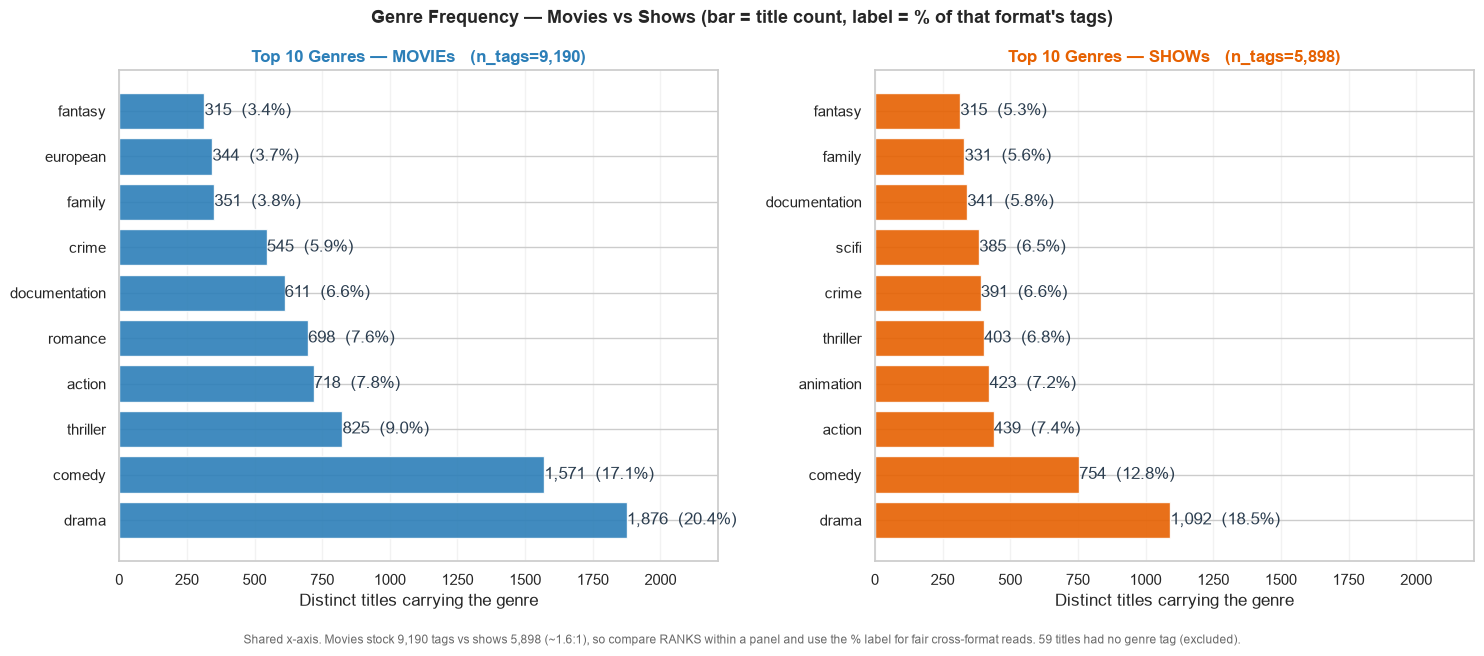

Top-10 in BOTH (universal staples): ['action', 'comedy', 'crime', 'documentation', 'drama', 'family', 'fantasy', 'thriller']
Top-10 in MOVIES only (film lane) : ['european', 'romance']
Top-10 in SHOWS only (series lane): ['animation', 'scifi']

Denominator check (bar vs treemap): {'MOVIE': 9190, 'SHOW': 5898} <- must match treemap panel totals


In [ ]:
import ast, numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns

sns.set_theme(style="whitegrid")


# ---- shared parser (identical to treemap/country so denominators reconcile) ----
def parse_list(x):
    if pd.isna(x):
        return []
    try:
        v = ast.literal_eval(x)
        return v if isinstance(v, list) else [v]
    except Exception:
        return [
            s.strip().strip("'\"") for s in str(x).strip("[] ").split(",") if s.strip()
        ]


t = titles_df[["id", "type", "genres"]].copy()
t["genres_l"] = t["genres"].apply(parse_list)
n_empty = int((t["genres_l"].str.len() == 0).sum())  # titles with NO genre tag
gx = t.explode("genres_l").dropna(subset=["genres_l"])
gx = gx[gx["genres_l"].astype(str).str.len() > 0]  # drop empties BEFORE denominators

# count DISTINCT titles per genre per type (nunique on the key, not size -> dup-safe)
cnt = (
    gx.groupby(["type", "genres_l"])["id"]
    .nunique()
    .rename("title_count")
    .reset_index()
    .rename(columns={"genres_l": "genre"})
)
tag_tot = gx.groupby("type").size()  # total genre-TAGS per type (= treemap denom)
cnt["pct_within_type"] = cnt.apply(
    lambda r: 100 * r["title_count"] / tag_tot[r["type"]], axis=1
)

# deterministic top-10 per format (ties broken by genre name asc)
top = (
    cnt.sort_values(["type", "title_count", "genre"], ascending=[True, False, True])
    .groupby("type", group_keys=False)
    .head(10)
)

C = {"MOVIE": "#2C7FB8", "SHOW": "#E66101"}
xmax = top["title_count"].max() * 1.18  # shared scale + label headroom

fig, axes = plt.subplots(1, 2, figsize=(15, 6.5), sharex=True)
for ax, typ in zip(axes, ["MOVIE", "SHOW"]):
    d = top[top["type"] == typ].sort_values(
        "title_count"
    )  # ascending so #1 lands on top
    bars = ax.barh(
        d["genre"], d["title_count"], color=C[typ], alpha=0.9, edgecolor="white"
    )
    for b, n, p in zip(bars, d["title_count"], d["pct_within_type"]):
        ax.text(
            b.get_width() + xmax * 0.0001,
            b.get_y() + b.get_height() / 2,
            f"{n:,}  ({p:.1f}%)",
            va="center",
            fontsize=12,
            color="#2C3E50"
        )
    ax.set_title(
        f"Top 10 Genres — {typ}s   (n_tags={int(tag_tot[typ]):,})",
        fontsize=12,
        fontweight="bold",
        color=C[typ],
    )
    ax.set_xlabel("Distinct titles carrying the genre")
    ax.invert_yaxis()
    ax.grid(axis="x", alpha=0.25)
axes[0].set_xlim(0, xmax)
fig.suptitle(
    "Genre Frequency — Movies vs Shows (bar = title count, label = % of that format's tags)",
    fontsize=13,
    fontweight="bold",
)
fig.text(
    0.5,
    0.005,
    f"Shared x-axis. Movies stock {int(tag_tot['MOVIE']):,} tags vs shows {int(tag_tot['SHOW']):,} "
    f"(~{tag_tot['MOVIE']/tag_tot['SHOW']:.1f}:1), so compare RANKS within a panel and use the % label "
    f"for fair cross-format reads. {n_empty} titles had no genre tag (excluded).",
    ha="center",
    fontsize=8.5,
    color="dimgray",
)
plt.tight_layout(rect=[0, 0.03, 1, 1])
plt.savefig("./assets/top10_genres_by_type.png", dpi=150)
plt.show()

# ---- the actual insight: where the two top-10s agree vs diverge ----
m_set, s_set = set(top[top["type"] == "MOVIE"]["genre"]), set(
    top[top["type"] == "SHOW"]["genre"]
)
print("Top-10 in BOTH (universal staples):", sorted(m_set & s_set))
print("Top-10 in MOVIES only (film lane) :", sorted(m_set - s_set))
print("Top-10 in SHOWS only (series lane):", sorted(s_set - m_set))

# ---- reconciliation: this bar's per-type tag total MUST equal the treemap's n_tags ----
print(
    "\nDenominator check (bar vs treemap):",
    {k: int(v) for k, v in tag_tot.items()},
    "<- must match treemap panel totals",
)

### Box-plot IMDB score by content type

Ungated rated titles: 5,368  ->  gated (>= 100 votes): 4,902
  MOVIE: n 3,429->3,142 | scores>=9.5 0->0 (gate strips 0 low-vote artifacts)
  SHOW: n 1,939->1,760 | scores>=9.5 3->2 (gate strips 1 low-vote artifacts)

Per-format distribution (gated):
            n  median  mean   Q1   Q3  IQR   std  lower_fence  upper_fence  outliers_below  outliers_above  min  max  %<5 (flop mass)  %>8.5 (breakout mass)
MOVIE  3142.0     6.4  6.26  5.6  7.1  1.5  1.11         3.35         9.35            47.0             0.0  1.5  9.1            11.27                   0.45
SHOW   1760.0     7.1  7.00  6.4  7.7  1.3  1.06         4.45         9.65            40.0             0.0  2.0  9.5             4.09                   4.20


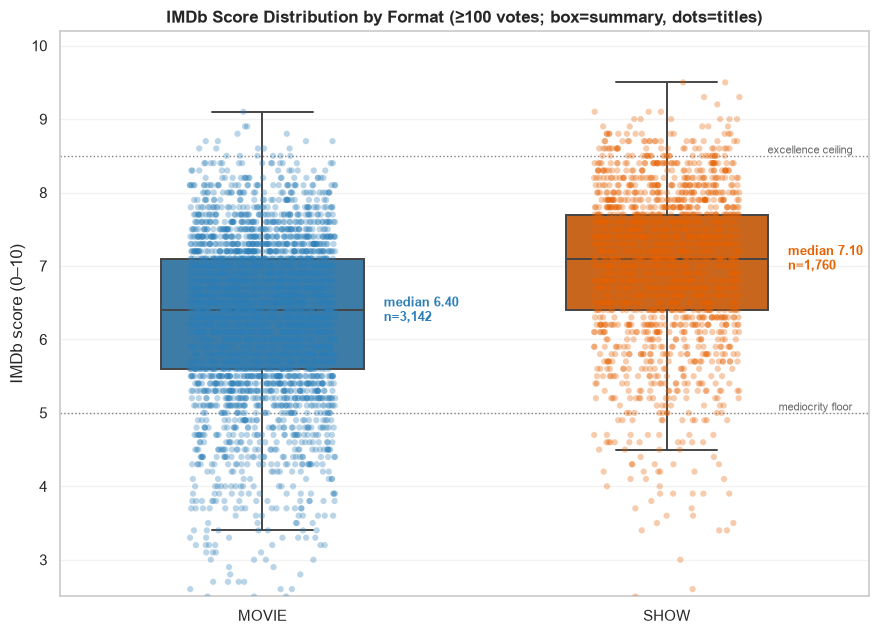

In [ ]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns

sns.set_theme(style="whitegrid")

MIN_VOTES = 100
C = {"MOVIE": "#2C7FB8", "SHOW": "#E66101"}
ORDER = ["MOVIE", "SHOW"]

g = titles_df.copy()
for c in ["imdb_score", "imdb_votes"]:
    g[c] = pd.to_numeric(g[c], errors="coerce")

# ---- gate (same as histogram / decade line) ----
raw = g.dropna(subset=["imdb_score"])
gg = raw[raw["imdb_votes"] >= MIN_VOTES].copy()
print(
    f"Ungated rated titles: {len(raw):,}  ->  gated (>= {MIN_VOTES} votes): {len(gg):,}"
)
for typ in ORDER:
    u = raw[raw["type"] == typ]
    q = gg[gg["type"] == typ]
    hi_u = (u["imdb_score"] >= 9.5).sum()
    hi_q = (q["imdb_score"] >= 9.5).sum()
    print(
        f"  {typ}: n {len(u):,}->{len(q):,} | scores>=9.5 {hi_u}->{hi_q} "
        f"(gate strips {hi_u-hi_q} low-vote artifacts)"
    )


# ---- five-number + fence stats (the analytical payload) ----
def stats(s):
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return pd.Series(
        {
            "n": len(s),
            "median": s.median(),
            "mean": s.mean(),
            "Q1": q1,
            "Q3": q3,
            "IQR": iqr,
            "std": s.std(),
            "lower_fence": lo,
            "upper_fence": hi,
            "outliers_below": int((s < lo).sum()),
            "outliers_above": int((s > hi).sum()),
            "min": s.min(),
            "max": s.max(),
            "%<5 (flop mass)": (s < 5).mean() * 100,
            "%>8.5 (breakout mass)": (s > 8.5).mean() * 100,
        }
    )



tab = pd.DataFrame(
    {typ: stats(gg.loc[gg["type"] == typ, "imdb_score"]) for typ in ORDER}
).T
print("\nPer-format distribution (gated):")
print(tab.round(2).to_string())

# ---- plot: box (summary) + strip (shape), shared thresholds ----
fig, ax = plt.subplots(figsize=(9, 6.5))
sns.boxplot(
    data=gg,
    x="type",
    y="imdb_score",
    order=ORDER,
    hue="type",
    palette=C,
    width=0.5,
    fliersize=0,
    linewidth=1.4,
    legend=False,
    ax=ax,
)
sns.stripplot(
    data=gg,
    x="type",
    y="imdb_score",
    order=ORDER,
    hue="type",
    palette=C,
    size=4.5,
    alpha=0.32,
    jitter=0.18,
    linewidth=0,
    legend=False,
    ax=ax,
)

# median + n labels on each box
for i, typ in enumerate(ORDER):
    med = tab.loc[typ, "median"]
    n = int(tab.loc[typ, "n"])
    ax.annotate(
        f"median {med:.2f}\nn={n:,}",
        (i, med),
        xytext=(i + 0.30, med),
        fontsize=9,
        fontweight="bold",
        color=C[typ],
        va="center",
    )

# reuse histogram thresholds for cross-chart coherence
for x, lab in [(5.0, "mediocrity floor"), (8.5, "excellence ceiling")]:
    ax.axhline(x, color="grey", ls=":", lw=1.0)
    ax.text(1.46, x, lab, ha="right", va="bottom", fontsize=8, color="dimgray")

ax.set_xlabel("")
ax.set_ylabel("IMDb score (0–10)")
ax.set_ylim(2.5, 10.2)
ax.set_title(
    "IMDb Score Distribution by Format (≥100 votes; box=summary, dots=titles)",
    fontsize=12.5,
    fontweight="bold",
)
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.savefig("./assets/boxplot_score_by_type.png", dpi=150)
plt.show()

### Correlation heatmap — Numerical relationships

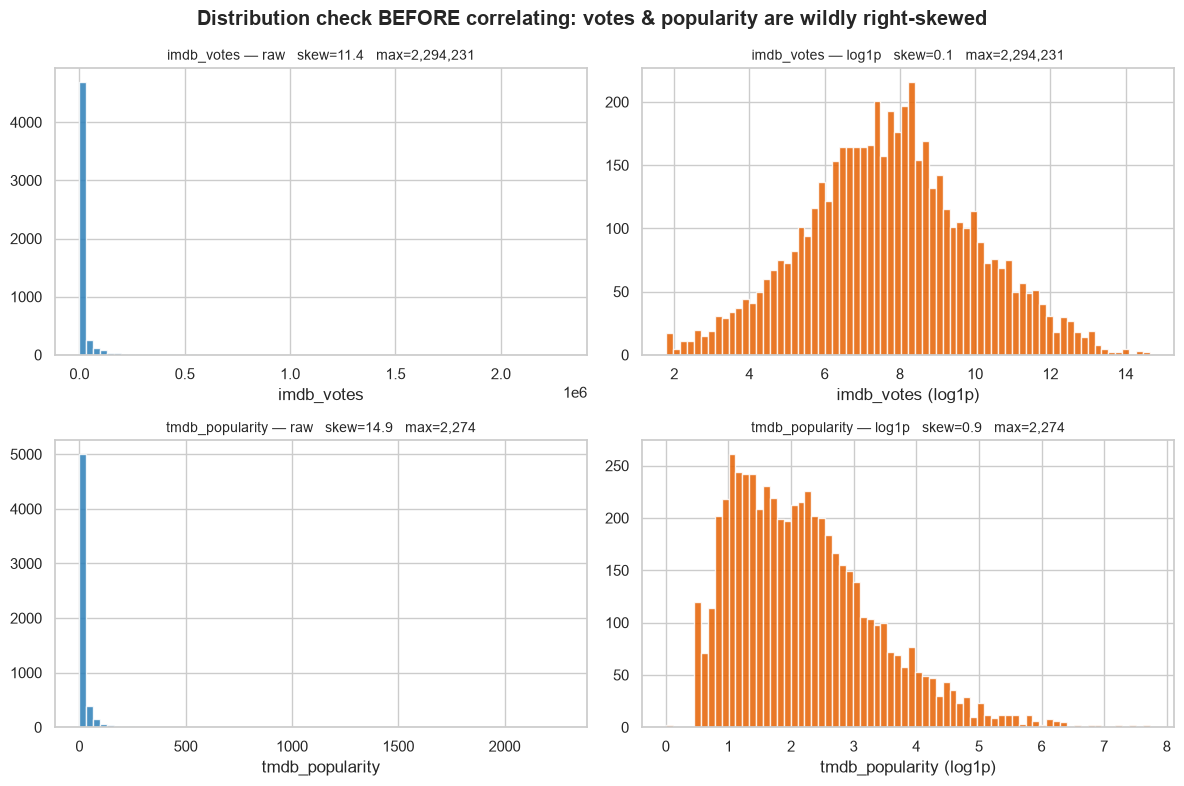

Skew report (|skew|>1 = strongly skewed; raw Pearson unreliable):
                      n   skew  kurtosis         max
imdb_score       5368.0  -0.63      0.65        9.60
tmdb_score       5539.0  -0.50      2.14       10.00
imdb_votes       5352.0  11.43    184.16  2294231.00
tmdb_popularity  5759.0  14.92    309.64     2274.04
runtime          5850.0   0.20     -0.57      240.00
release_year     5850.0  -3.57     18.05     2022.00
seasons          2106.0   7.01     74.55       42.00


In [ ]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns

sns.set_theme(style="whitegrid")

NUM = [
    "imdb_score",
    "tmdb_score",
    "imdb_votes",
    "tmdb_popularity",
    "runtime",
    "release_year",
]
df = titles_df.copy()
for c in NUM + ["seasons"]:
    df[c] = pd.to_numeric(df[c], errors="coerce")

# raw vs log1p for the two heavily-skewed reach metrics
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, (col, tr) in zip(
    axes.ravel(),
    [
        ("imdb_votes", "raw"),
        ("imdb_votes", "log1p"),
        ("tmdb_popularity", "raw"),
        ("tmdb_popularity", "log1p"),
    ],
):
    s = df[col].dropna()
    x = np.log1p(s) if tr == "log1p" else s
    ax.hist(x, bins=70, color="#E66101" if tr == "log1p" else "#2C7FB8", alpha=0.85)
    ax.set_title(
        f"{col} — {tr}   skew={x.skew():.1f}   max={s.max():,.0f}", fontsize=10
    )
    ax.set_xlabel(col + (" (log1p)" if tr == "log1p" else ""))
plt.suptitle(
    "Distribution check BEFORE correlating: votes & popularity are wildly right-skewed",
    fontweight="bold",
)
plt.tight_layout()
plt.savefig("./assets/dist_check_skew.png", dpi=150)
plt.show()

# skew/kurtosis for every numeric -> justifies Spearman (or log-Pearson) over raw Pearson
skew_tbl = (
    df[NUM + ["seasons"]]
    .apply(
        lambda s: pd.Series(
            {
                "n": int(s.notna().sum()),
                "skew": s.skew(),
                "kurtosis": s.kurtosis(),
                "max": s.max(),
            }
        )
    )
    .T
)
print("Skew report (|skew|>1 = strongly skewed; raw Pearson unreliable):")
print(skew_tbl.round(2).to_string())

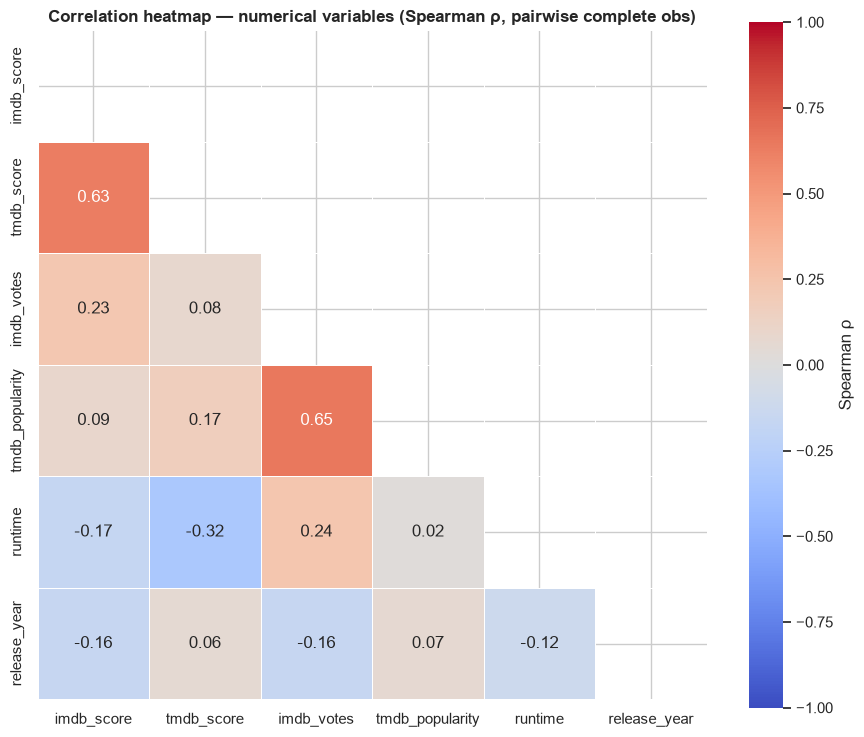

Pairwise n per cell (cells with small n = less reliable ρ):
                 imdb_score  tmdb_score  imdb_votes  tmdb_popularity  runtime  release_year
imdb_score             5368        5145        5352             5293     5368          5368
tmdb_score             5145        5539        5131             5539     5539          5539
imdb_votes             5352        5131        5352             5279     5352          5352
tmdb_popularity        5293        5539        5279             5759     5759          5759
runtime                5368        5539        5352             5759     5850          5850
release_year           5368        5539        5352             5759     5850          5850


In [ ]:
# pairwise-complete-obs Spearman on the variables that exist across BOTH formats
corr = df[NUM].corr(
    method="spearman"
)  # swap to: np.log1p(df[...]).corr("pearson") for log-Pearson
mask = np.triu(
    np.ones_like(corr, dtype=bool)
)  # show lower triangle only (matrix is symmetric)

fig, ax = plt.subplots(figsize=(9, 7.5))
sns.heatmap(
    corr,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=0.6,
    cbar_kws={"label": "Spearman ρ"},
    ax=ax,
)
ax.set_title(
    "Correlation heatmap — numerical variables (Spearman ρ, pairwise complete obs)",
    fontweight="bold",
    fontsize=12,
)
plt.tight_layout()
plt.savefig("./assets/corr_heatmap_spearman.png", dpi=150)
plt.show()


# THE reliability layer: per-cell n. Never read a ρ without its n.
def pairwise_n(d, cols):
    n = pd.DataFrame(index=cols, columns=cols, dtype=float)
    for a in cols:
        for b in cols:
            n.loc[a, b] = d[[a, b]].dropna().shape[0]
    return n


nmat = pairwise_n(df, NUM)
print("Pairwise n per cell (cells with small n = less reliable ρ):")
print(nmat.astype("Int64").to_string())

### Scatter plot — Popularity versus IMDb score

Scatter population: 5,293 titles (score & popularity both present); dropped 557 missing either. MOVIE n=3,379 | SHOW n=1,914


C:\Users\User\AppData\Local\Temp\ipykernel_16884\3895973790.py:118: UserWarning: Glyph 8209 (\N{NON-BREAKING HYPHEN}) missing from font(s) Arial.
  plt.tight_layout()
findfont: Failed to find font weight medium for Arial, now using 400.
C:\Users\User\AppData\Local\Temp\ipykernel_16884\3895973790.py:119: UserWarning: Glyph 8209 (\N{NON-BREAKING HYPHEN}) missing from font(s) Arial.
  plt.savefig("scatter_pop_vs_score.png", dpi=150)
C:\Users\User\AppData\Roaming\Python\Python311\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 8209 (\N{NON-BREAKING HYPHEN}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


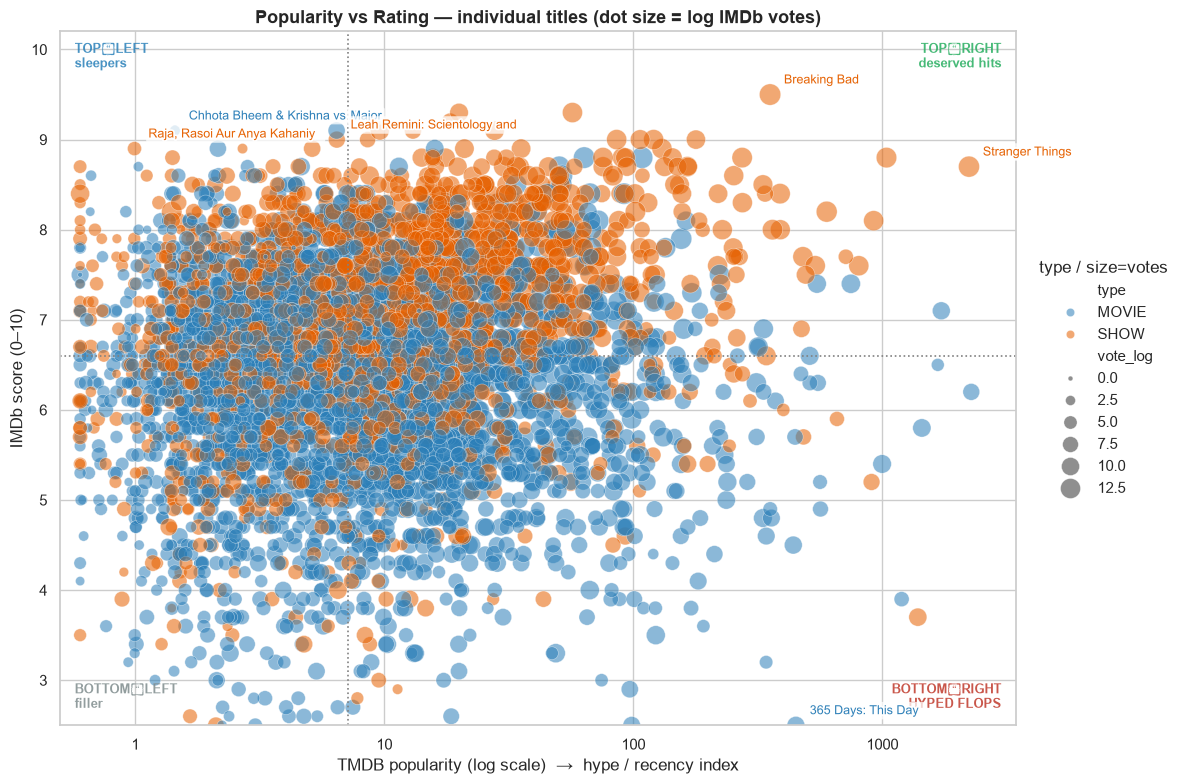


Medians (crosshair): popularity=7.2  score=6.60
Quadrant counts (share of scatter population):
quad
TR: deserved hits    26.8
TL: sleepers         25.6
BL: filler           24.4
BR: HYPED FLOPS      23.2

Spearman ρ (score vs popularity) on THIS population = +0.089  -> must match the heatmap cell for these two columns
Bottom-right (hyped flops) top offenders by popularity:
               title  type  tmdb_popularity  imdb_score  imdb_votes
         Incantation MOVIE         2274.044         6.2      5660.0
  Valley of the Dead MOVIE         1668.296         6.5       114.0
The Man from Toronto MOVIE         1439.906         5.8     31497.0
       Resident Evil  SHOW         1387.392         3.7     24982.0
           Collision MOVIE         1194.149         3.9       886.0
          Spiderhead MOVIE          996.869         5.4     43239.0


In [ ]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, matplotlib.patheffects as pe, seaborn as sns
from matplotlib.ticker import FuncFormatter

sns.set_theme(style="whitegrid")

C = {"MOVIE": "#2C7FB8", "SHOW": "#E66101"}
ORDER = ["MOVIE", "SHOW"]

# ---- population = score AND popularity present (SAME as the heatmap; NO votes gate) ----
sc = titles_df.copy()
for c in ["imdb_score", "tmdb_popularity", "imdb_votes"]:
    sc[c] = pd.to_numeric(sc[c], errors="coerce")
n0 = len(sc)
sc = sc.dropna(subset=["imdb_score", "tmdb_popularity"]).copy()
sc["vote_log"] = np.log1p(
    sc["imdb_votes"].fillna(0)
)  # NaN votes -> smallest dot (least confidence)
print(
    f"Scatter population: {len(sc):,} titles (score & popularity both present); "
    f"dropped {n0-len(sc):,} missing either. MOVIE n={(sc['type']=='MOVIE').sum():,} | "
    f"SHOW n={(sc['type']=='SHOW').sum():,}"
)

# ---- crosshair = catalog medians (title-level twin of the bubble chart) ----
med_pop, med_score = sc["tmdb_popularity"].median(), sc["imdb_score"].median()
sc["quad"] = np.select(
    [
        (sc.tmdb_popularity >= med_pop) & (sc.imdb_score >= med_score),
        (sc.tmdb_popularity >= med_pop) & (sc.imdb_score < med_score),
        (sc.tmdb_popularity < med_pop) & (sc.imdb_score >= med_score),
    ],
    ["TR: deserved hits", "BR: HYPED FLOPS", "TL: sleepers"],
    default="BL: filler",
)

# ---- plot ----
fig, ax = plt.subplots(figsize=(12, 8))
sns.scatterplot(
    data=sc,
    x="tmdb_popularity",
    y="imdb_score",
    hue="type",
    hue_order=ORDER,
    size="vote_log",
    sizes=(12, 240),
    alpha=0.55,
    edgecolor="white",
    linewidth=0.4,
    palette=C,
    ax=ax,
)
ax.set_xscale("log")
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:g}"))
ax.axvline(med_pop, color="grey", ls=":", lw=1.2)
ax.axhline(med_score, color="grey", ls=":", lw=1.2)
ax.set_ylim(2.5, 10.2)
ax.set_xlim(0.5, None)
ax.set_xlabel("TMDB popularity (log scale)  →  hype / recency index")
ax.set_ylabel("IMDb score (0–10)")
ax.set_title(
    "Popularity vs Rating — individual titles (dot size = log IMDb votes)",
    fontsize=13,
    fontweight="bold",
)

# quadrant captions in the corners
for xf, yf, txt, col in [
    (0.985, 0.985, "TOP‑RIGHT\ndeserved hits", "#27AE60"),
    (0.985, 0.02, "BOTTOM‑RIGHT\nHYPED FLOPS", "#C0392B"),
    (0.015, 0.985, "TOP‑LEFT\nsleepers", "#2980B9"),
    (0.015, 0.02, "BOTTOM‑LEFT\nfiller", "#7f8c8d"),
]:
    ax.text(
        xf,
        yf,
        txt,
        transform=ax.transAxes,
        ha="right" if xf > 0.5 else "left",
        va="top" if yf > 0.5 else "bottom",
        fontsize=9,
        fontweight="bold",
        color=col,
        alpha=0.85,
    )

# data-driven exemplar labels (farthest from centre in each quadrant)
ctr = np.array([np.log10(med_pop), med_score])

for q, k in [("TR: deserved hits", 2), ("BR: HYPED FLOPS", 4), ("TL: sleepers", 4)]:
    sub = sc[sc.quad == q].copy()
    sub["d"] = np.hypot(np.log10(sub.tmdb_popularity) - ctr[0], sub.imdb_score - ctr[1])

    for _, r in sub.nlargest(k, "d").iterrows():
        ax.annotate(
            r["title"][:28],
            (r["tmdb_popularity"], r["imdb_score"]),
            textcoords="offset points",
            xytext=(10, 8),
            fontsize=9,
            fontweight="medium",
            color=C.get(r["type"], "black"),
            bbox=dict(
                boxstyle="round,pad=0.18",
                facecolor="white",
                edgecolor="none",
                alpha=0.75,
            ),
            path_effects=[pe.withStroke(linewidth=2.5, foreground="white")],
            alpha=0.98,
        )
ax.legend(
    loc="center left",
    bbox_to_anchor=(1.01, 0.5),
    title="type / size=votes",
    frameon=False,
)
plt.tight_layout()
plt.savefig("./assets/scatter_pop_vs_score.png", dpi=150)
plt.show()

# ---- the numbers the chart is arguing ----
print(f"\nMedians (crosshair): popularity={med_pop:.1f}  score={med_score:.2f}")
print("Quadrant counts (share of scatter population):")
print((sc.quad.value_counts(normalize=True) * 100).round(1).to_string())
rho = sc[["imdb_score", "tmdb_popularity"]].corr(method="spearman").iloc[0, 1]
print(
    f"\nSpearman ρ (score vs popularity) on THIS population = {rho:+.3f}  "
    f"-> must match the heatmap cell for these two columns"
)
print("Bottom-right (hyped flops) top offenders by popularity:")
print(
    sc[sc.quad == "BR: HYPED FLOPS"]
    .nlargest(6, "tmdb_popularity")[
        ["title", "type", "tmdb_popularity", "imdb_score", "imdb_votes"]
    ]
    .to_string(index=False)
)

### 100% stacked bar chart — Age certification mix

Raw-label x type crosstab (note the zero-blocks = two different systems):
cert     G  NC-17   PG  PG-13    R  TV-14  TV-G  TV-MA  TV-PG  TV-Y  TV-Y7  Uncertified
type                                                                                   
MOVIE  124     16  233    451  556      0     0      0      0     0      0         2364
SHOW     0      0    0      0    0    474    79    883    188   107    120          255

Certification coverage (the reason Uncertified must stay visible):
  MOVIE: 1,380/3,744 = 36.9% carry a label
  SHOW: 1,851/2,106 = 87.9% carry a label


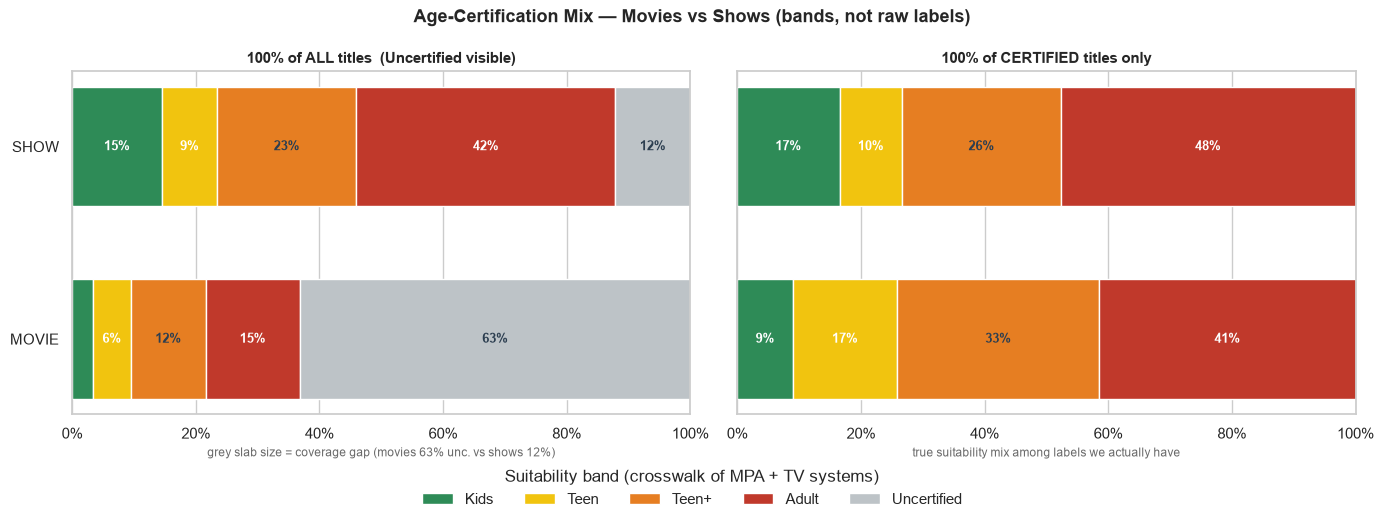


Band shares (all-titles vs certified-only):
             MOVIE_all%  SHOW_all%  MOVIE_cert%  SHOW_cert%
band                                                       
Kids                3.3       14.5          9.0        16.5
Teen                6.2        8.9         16.9        10.2
Teen+              12.0       22.5         32.7        25.6
Adult              15.3       41.9         41.4        47.7
Uncertified        63.1       12.1          0.0         0.0


In [ ]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns

sns.set_theme(style="whitegrid")

t = titles_df.copy()
# blank -> explicit 'Uncertified' bucket (NOT dropped, NOT called 'unrated')
t["cert"] = t["age_certification"].fillna("Uncertified").astype(str).str.strip()

BAND = {  # raw label -> suitability band  (the crosswalk above)
    "G": "Kids",
    "TV-Y": "Kids",
    "TV-Y7": "Kids",
    "TV-G": "Kids",
    "PG": "Teen",
    "TV-PG": "Teen",
    "PG-13": "Teen+",
    "TV-14": "Teen+",
    "R": "Adult",
    "NC-17": "Adult",
    "TV-MA": "Adult",
    "Uncertified": "Uncertified",
}
ORDER = [
    "Kids",
    "Teen",
    "Teen+",
    "Adult",
    "Uncertified",
]  # suitability order, unknown last
COL = {
    "Kids": "#2E8B57",
    "Teen": "#F1C40F",
    "Teen+": "#E67E22",
    "Adult": "#C0392B",
    "Uncertified": "#BDC3C7",
}  # ramp + neutral grey for "we don't know"

t["band"] = t["cert"].map(BAND)
assert (
    t["band"].notna().all()
), "a raw label escaped the crosswalk — inspect t['cert'].unique()"


# two denominators, on purpose
def shares(denominator):  # denominator: 'ALL' or 'CERTIFIED'
    sub = t if denominator == "ALL" else t[t["band"] != "Uncertified"]
    ct = pd.crosstab(sub["type"], sub["band"]).reindex(columns=ORDER, fill_value=0)
    return (ct.div(ct.sum(axis=1), axis=0) * 100), ct.sum(axis=1)


all_pct, all_n = shares("ALL")
cert_pct, cert_n = shares("CERTIFIED")

# ---- audit: prove the disjointness + the coverage gap in numbers ----
print("Raw-label x type crosstab (note the zero-blocks = two different systems):")
print(pd.crosstab(t["type"], t["cert"]).to_string())
print("\nCertification coverage (the reason Uncertified must stay visible):")
for typ in ["MOVIE", "SHOW"]:
    d = t[t["type"] == typ]
    print(
        f"  {typ}: {int((d['band']!='Uncertified').sum()):,}/{len(d):,} "
        f"= {(d['band']!='Uncertified').mean()*100:.1f}% carry a label"
    )

# ---- 2-panel 100% stacked barh ----
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2), sharey=True)
for ax, (pct, ttl, note) in zip(
    axes,
    [
        (
            all_pct,
            "100% of ALL titles  (Uncertified visible)",
            "grey slab size = coverage gap (movies 63% unc. vs shows 12%)",
        ),
        (
            cert_pct,
            "100% of CERTIFIED titles only",
            "true suitability mix among labels we actually have",
        ),
    ],
):
    left = np.zeros(len(pct))
    types = pct.index.tolist()  # ['MOVIE','SHOW']
    for b in ORDER:
        vals = pct[b].values
        bars = ax.barh(
            types,
            vals,
            left=left,
            color=COL[b],
            label=b,
            edgecolor="white",
            height=0.62,
        )
        for rect, v, l in zip(bars, vals, left):
            if v >= 4:  # only annotate readable slabs
                ax.text(
                    l + v / 2,
                    rect.get_y() + rect.get_height() / 2,
                    f"{v:.0f}%",
                    ha="center",
                    va="center",
                    fontsize=9,
                    fontweight="bold",
                    color="white" if b in ("Adult", "Teen", "Kids") else "#2C3E50",
                )
        left += vals
    ax.set_xlim(0, 100)
    ax.set_title(ttl, fontsize=11, fontweight="bold")
    ax.set_xlabel(note, fontsize=8.5, color="dimgray")
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.0f}%"))
    ax.invert_yaxis()
axes[0].set_ylabel("")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(
    handles,
    labels,
    loc="lower center",
    ncol=5,
    frameon=False,
    title="Suitability band (crosswalk of MPA + TV systems)",
)
fig.suptitle(
    "Age-Certification Mix — Movies vs Shows (bands, not raw labels)",
    fontsize=13,
    fontweight="bold",
)
plt.tight_layout(rect=[0, 0.08, 1, 1])
plt.savefig("./assets/cert_mix_100pct.png", dpi=150)
plt.show()

# ---- the band table the chart is arguing ----
tbl = pd.DataFrame(
    {
        "MOVIE_all%": all_pct.loc["MOVIE"].round(1),
        "SHOW_all%": all_pct.loc["SHOW"].round(1),
        "MOVIE_cert%": cert_pct.loc["MOVIE"].round(1),
        "SHOW_cert%": cert_pct.loc["SHOW"].round(1),
    }
)
print("\nBand shares (all-titles vs certified-only):")
print(tbl.to_string())